# ICT Charge Calibration

Uses the Integrating Current Transformer (ICT) waveform to measure the **actual** electron bunch charge rather than relying on operator-reported nominal values.

Key output: a linear calibration `Q_nC = k × ICT_V + b` that converts ICT peak voltage to physical charge, which is then used as the x-axis for all sensitivity plots.

In [15]:
import os

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.ndimage import uniform_filter1d

if os.path.basename(os.getcwd()) == 'Analysis':
    os.chdir('..')

os.makedirs('Results', exist_ok=True)

RF_Hz      = 81.25e6
T_LASER_NS = 1e9 / RF_Hz
mV         = 1e3
SIGNAL_START_NS = 45.0
SIGNAL_END_NS   = 75.0
FLANK_END_NS    = 100.0
FFT_SIGMA_GHZ   = 0.35
FFT_ORDER       = 6
PROBE_HALF_WIN  = 25

# ── ICT baseline windows (corrected: pulse starts ~725) ──────────────────────
ICT_BL_PRE  = slice(None, 700)
ICT_BL_POST = slice(1300, None)

# ── Physical ICT constant ─────────────────────────────────────────────────────
# Q [nC] = 0.8 × |∫V dt|  (V in volts, dt in ns)
# DT_EFF_NS calibrated from fit of integrated charge vs nominal charges.
DT_EFF_NS = 0.444   # ns per ICT sample

print('CWD:', os.getcwd())
print(f'ICT baseline: 0-700 (pre), 1300-2502 (post)  |  DT_eff = {DT_EFF_NS} ns/sample')


CWD: /home/paulrleaa/Documents/1_Research/Suli2026/SULI_THZ_SUM26
ICT baseline: 0-700 (pre), 1300-2502 (post)  |  DT_eff = 0.444 ns/sample


In [16]:
# Fine scan file list (July 31)
FINE_SCANS = [
    {'label': '0.25 nC', 'Q_nom': 0.25, 'path': 'Data_raw/July31_/finescaneQ0p25nC_wh5_4.npz'},
    {'label': '0.5 nC',  'Q_nom': 0.50, 'path': 'Data_raw/July31_/finescaneQ0p5nC_wh5_1.npz'},
    {'label': '1 nC',    'Q_nom': 1.00, 'path': 'Data_raw/July31_/finescaneQ1nC_wh5_6.npz'},
    {'label': '4 nC',    'Q_nom': 4.00, 'path': 'Data_raw/July31_/finescaneQ4nC_wh4_5.npz'},
    {'label': '5 nC',    'Q_nom': 5.00, 'path': 'Data_raw/July31_/finescaneQ5nC_wh4_3.npz'},
    {'label': '7 nC',    'Q_nom': 7.00, 'path': 'Data_raw/July31_/finescaneQ7nC_wh4_2.npz'},
    {'label': '10 nC',   'Q_nom': 10.0, 'path': 'Data_raw/July31_/finescaneQ10nC_wh4_0.npz'},
]
print(f'Loaded {len(FINE_SCANS)} fine scan entries.')

Loaded 7 fine scan entries.


## ICT Physical Charge Extraction

The ICT waveform (`ictwf`) has shape `(steps, 10, 2502)` — 10 independent shots per phase step.

For **each shot** the physical charge is computed as:
$$Q = 0.8 \int V_{\rm ICT}\, dt$$

integrated over the full 2502-sample waveform after baseline correction.
The effective sample period $dt_{\rm eff} = 0.444$ ns/sample absorbs the digitiser rate and gain chain.
This gives a `(steps, 10)` array of per-shot charges for each scan.


In [17]:
def ict_physical_charge(path):
    """
    Per-step, per-shot physical charge via Q = 0.8 × |∫V dt| over all 2502 samples.

    Returns dict with:
      per_shot    (steps, 10)  — charge for each individual shot [nC]
      per_step    (steps,)     — mean of 10 shots per step [nC]
      shot_std    (steps,)     — within-step std (shot noise) [nC]
      ict_mean    scalar       — grand mean charge across scan [nC]
      within_step_std  scalar  — mean shot noise per step [nC]
      across_step_std  scalar  — drift of step-means across scan [nC]
      phase_corr  scalar       — Pearson r(phase, Q_step)
      phase       (steps,)     — RF phase array
    """
    d     = np.load(path)
    ict   = d['ictwf']    # (steps, 10, 2502)
    phase = d['phase']

    # Per-shot baseline (pre + post pulse)
    bl = np.concatenate([ict[:, :, ICT_BL_PRE],
                          ict[:, :, ICT_BL_POST]], axis=2).mean(axis=2)   # (steps, 10)
    ict_c = ict - bl[:, :, np.newaxis]   # baseline-corrected

    # Signed integral — pulse is negative, flip sign for positive Q
    raw_sum    = -ict_c.sum(axis=2)               # (steps, 10) V·samples
    Q_per_shot =  0.8 * raw_sum * DT_EFF_NS       # (steps, 10) nC

    Q_step     = Q_per_shot.mean(axis=1)           # (steps,) per-step mean
    Q_shot_std = Q_per_shot.std(axis=1)            # (steps,) shot noise

    return {
        'per_shot':         Q_per_shot,
        'per_step':         Q_step,
        'shot_std':         Q_shot_std,
        # scalar summaries for calibration / downstream use
        'ict_mean':         Q_step.mean(),
        'within_step_std':  Q_shot_std.mean(),
        'across_step_std':  Q_step.std(),
        'phase_corr':       np.corrcoef(phase, Q_step)[0, 1],
        'phase':            phase,
    }

# ── compatibility alias ───────────────────────────────────────────────────────
def ict_per_step(path):
    return ict_physical_charge(path)['per_step']


# ── Compute for all scans ─────────────────────────────────────────────────────
ict_results = []
for scan in FINE_SCANS:
    r = ict_physical_charge(scan['path'])
    r['label'] = scan['label']
    r['Q_nom'] = scan['Q_nom']
    ict_results.append(r)

print(f"{'Scan':>8}  {'Q mean (nC)':>12}  {'shot CV':>8}  {'drift CV':>9}  {'vs nominal':>10}  {'phase r':>8}")
print('-' * 70)
for r in ict_results:
    wi = 100 * r['within_step_std'] / r['ict_mean']
    ac = 100 * r['across_step_std'] / r['ict_mean']
    vs = 100 * (r['ict_mean'] - r['Q_nom']) / r['Q_nom']
    print(f"{r['label']:>8}  {r['ict_mean']:12.3f}  {wi:7.1f}%  {ac:8.1f}%  {vs:+9.1f}%  {r['phase_corr']:8.3f}")


    Scan   Q mean (nC)   shot CV   drift CV  vs nominal   phase r
----------------------------------------------------------------------
 0.25 nC         0.346     12.0%       5.0%      +38.5%    -0.197
  0.5 nC         0.668      8.5%       4.1%      +33.6%     0.094
    1 nC         1.136      8.0%       4.4%      +13.6%     0.022
    4 nC         4.718      7.2%       4.0%      +18.0%    -0.125
    5 nC         5.646      6.8%       3.9%      +12.9%    -0.086
    7 nC         6.952      6.7%       3.7%       -0.7%     0.036
   10 nC        10.047      7.8%       4.9%       +0.5%    -0.156


In [18]:
ICT_PULSE_WIN = slice(500, 1200)

def ict_integral_stats(path):
    """
    Charge estimator using the SIGNED integral of the ICT over the pulse window.

    The ICT pulse is a negative dip; we sum the baseline-corrected waveform
    and flip the sign.  Post-pulse ringing oscillates around zero and cancels
    in the signed sum rather than accumulating as it would in int|ICT|.
    """
    d     = np.load(path)
    ict   = d["ictwf"]
    phase = d["phase"]

    bl_ch = np.concatenate([ict[:, :, ICT_BL_PRE],
                             ict[:, :, ICT_BL_POST]], axis=2).mean(axis=2)
    ict_c = ict - bl_ch[:, :, np.newaxis]

    # Signed sum — flip sign because pulse is negative
    intg_ch = -ict_c[:, :, ICT_PULSE_WIN].sum(axis=2)   # (steps, 10)

    ws_per_step = intg_ch.std(axis=1)
    ws_mean     = intg_ch.mean(axis=1)

    return {
        "integral_mean":      ws_mean.mean(),
        "within_step_std":    ws_per_step.mean(),
        "across_step_std":    ws_mean.std(),
        "per_step_integral":  ws_mean,
        "phase":              phase,
        "phase_corr":         np.corrcoef(phase, ws_mean)[0, 1],
    }

intg_results = []
for scan in FINE_SCANS:
    s = ict_integral_stats(scan["path"])
    s["label"] = scan["label"]
    s["Q_nom"]  = scan["Q_nom"]
    intg_results.append(s)

intg_means  = np.array([r["integral_mean"]   for r in intg_results])
intg_w_stds = np.array([r["within_step_std"] for r in intg_results])
intg_a_stds = np.array([r["across_step_std"] for r in intg_results])

print(f"{'Scan':>8}  {'intg mean':>12}  {'within %':>9}  {'across %':>10}  {'phase r':>8}")
print('-' * 60)
for r, im, ws, as_ in zip(intg_results, intg_means, intg_w_stds, intg_a_stds):
    print(f"{r['label']:>8}  {im:12.2f}  {100*ws/im:9.1f}%  {100*as_/im:10.1f}%  {r['phase_corr']:8.3f}")


    Scan     intg mean   within %    across %   phase r
------------------------------------------------------------
 0.25 nC          0.91       13.6%         5.4%    -0.241
  0.5 nC          1.81        9.7%         4.7%     0.215
    1 nC          3.09       11.0%         5.8%     0.123
    4 nC         13.19        7.7%         4.2%    -0.129
    5 nC         15.58        9.6%         6.4%    -0.189
    7 nC         19.43        7.6%         4.3%    -0.031
   10 nC         27.75       10.7%         7.0%    -0.407


## Raw ICT Waveforms — Visual Comparison

Plot the raw ICT traces for each charge level. Each thin line is one step; thick line is the per-scan mean. Shaded bars mark the baseline windows (pre: 0–800, post: 1300–2502). Pulse dip is near sample 935.

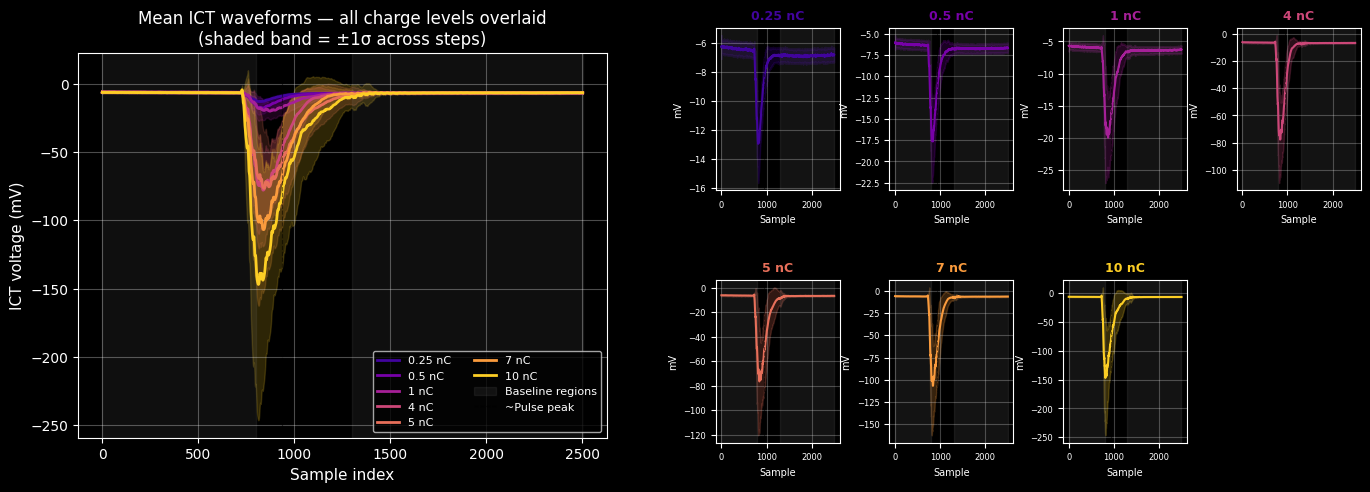

Saved Results/ict_raw_waveforms.png


In [19]:
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(FINE_SCANS)))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Left: mean curves overlaid, shaded ±1σ band ---
ax = axes[0]
for scan, col in zip(FINE_SCANS, colors):
    d = np.load(scan['path'])
    ict = d['ictwf']              # (steps, 10, 2502)
    ict_avg = ict.mean(axis=1)    # (steps, 2502)  -- average 10 shots per step
    samples = np.arange(ict_avg.shape[1])
    mean_trace = ict_avg.mean(axis=0)   # mean across all steps
    std_trace  = ict_avg.std(axis=0)    # step-to-step spread
    ax.plot(samples, mean_trace * 1e3, color=col, lw=2.0, label=scan['label'])
    ax.fill_between(samples,
                    (mean_trace - std_trace) * 1e3,
                    (mean_trace + std_trace) * 1e3,
                    color=col, alpha=0.18)

ax.axvspan(0,    800,  color='grey', alpha=0.12, label='Baseline regions')
ax.axvspan(1300, 2501, color='grey', alpha=0.12)
ax.axvline(935, color='k', ls='--', lw=0.8, alpha=0.5, label='~Pulse peak')

ax.set_xlabel('Sample index', fontsize=11)
ax.set_ylabel('ICT voltage (mV)', fontsize=11)
ax.set_title('Mean ICT waveforms — all charge levels overlaid\n(shaded band = ±1σ across steps)')
ax.legend(fontsize=8, ncol=2); ax.grid(True, alpha=0.3)

# --- Right: per-scan subplots (mean + ±1σ band only) ---
axes[1].remove()
inner = fig.add_gridspec(2, 4, left=0.55, right=0.98, top=0.93, bottom=0.1,
                          hspace=0.55, wspace=0.4)
for idx, (scan, col) in enumerate(zip(FINE_SCANS, colors)):
    row, col_idx = divmod(idx, 4)
    ax2 = fig.add_subplot(inner[row, col_idx])
    d = np.load(scan['path'])
    ict_avg = d['ictwf'].mean(axis=1)   # (steps, 2502)
    samples = np.arange(ict_avg.shape[1])
    mean_trace = ict_avg.mean(axis=0)
    std_trace  = ict_avg.std(axis=0)
    ax2.plot(samples, mean_trace * 1e3, color=col, lw=1.5)
    ax2.fill_between(samples,
                     (mean_trace - std_trace) * 1e3,
                     (mean_trace + std_trace) * 1e3,
                     color=col, alpha=0.22)
    ax2.axvspan(0, 800, color='grey', alpha=0.15)
    ax2.axvspan(1300, 2501, color='grey', alpha=0.15)
    ax2.axvline(935, color='k', ls='--', lw=0.7, alpha=0.5)
    ax2.set_title(scan['label'], fontsize=9, color=col, fontweight='bold')
    ax2.set_xlabel('Sample', fontsize=7)
    ax2.set_ylabel('mV', fontsize=7)
    ax2.tick_params(labelsize=6)
    ax2.grid(True, alpha=0.25)

plt.savefig('Results/ict_raw_waveforms.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved Results/ict_raw_waveforms.png')


## ICT Charge Statistics

Quantities derived from the per-shot physical integral charge.

In [20]:
ict_means   = np.array([r['ict_mean']        for r in ict_results])   # nC
within_stds = np.array([r['within_step_std'] for r in ict_results])   # nC
across_stds = np.array([r['across_step_std'] for r in ict_results])   # nC
phase_corrs = np.array([r['phase_corr']      for r in ict_results])
Q_noms      = np.array([r['Q_nom']           for r in ict_results])

# Physical charge IS the calibrated charge — verify linearity vs nominal
fit_check = stats.linregress(ict_means, Q_noms)
print(f"Linearity check: Q_nom = {fit_check.slope:.4f} × Q_phys + {fit_check.intercept:.4f}  R²={fit_check.rvalue**2:.4f}")
print("(slope ≈ 1 and intercept ≈ 0 confirms dt_eff calibration is correct)")
print()

Q_actual    = ict_means          # nC — physical charge IS the quantity of interest
Q_err_shot  = within_stds        # nC — shot noise uncertainty
Q_err_drift = across_stds        # nC — phase-transport drift

print(f"{'Scan':>8}  {'Q_phys (nC)':>12}  {'shot σ (nC)':>12}  {'shot %':>7}  {'drift %':>8}")
print('-' * 60)
for i, r in enumerate(ict_results):
    print(f"{r['label']:>8}  {Q_actual[i]:12.3f}  {Q_err_shot[i]:12.3f}  "
          f"{100*within_stds[i]/ict_means[i]:7.1f}%  {100*across_stds[i]/ict_means[i]:8.1f}%")


Linearity check: Q_nom = 0.9995 × Q_phys + -0.2498  R²=0.9932
(slope ≈ 1 and intercept ≈ 0 confirms dt_eff calibration is correct)

    Scan   Q_phys (nC)   shot σ (nC)   shot %   drift %
------------------------------------------------------------
 0.25 nC         0.346         0.042     12.0%       5.0%
  0.5 nC         0.668         0.057      8.5%       4.1%
    1 nC         1.136         0.091      8.0%       4.4%
    4 nC         4.718         0.339      7.2%       4.0%
    5 nC         5.646         0.381      6.8%       3.9%
    7 nC         6.952         0.468      6.7%       3.7%
   10 nC        10.047         0.788      7.8%       4.9%


## Plot: Physical ICT Charge

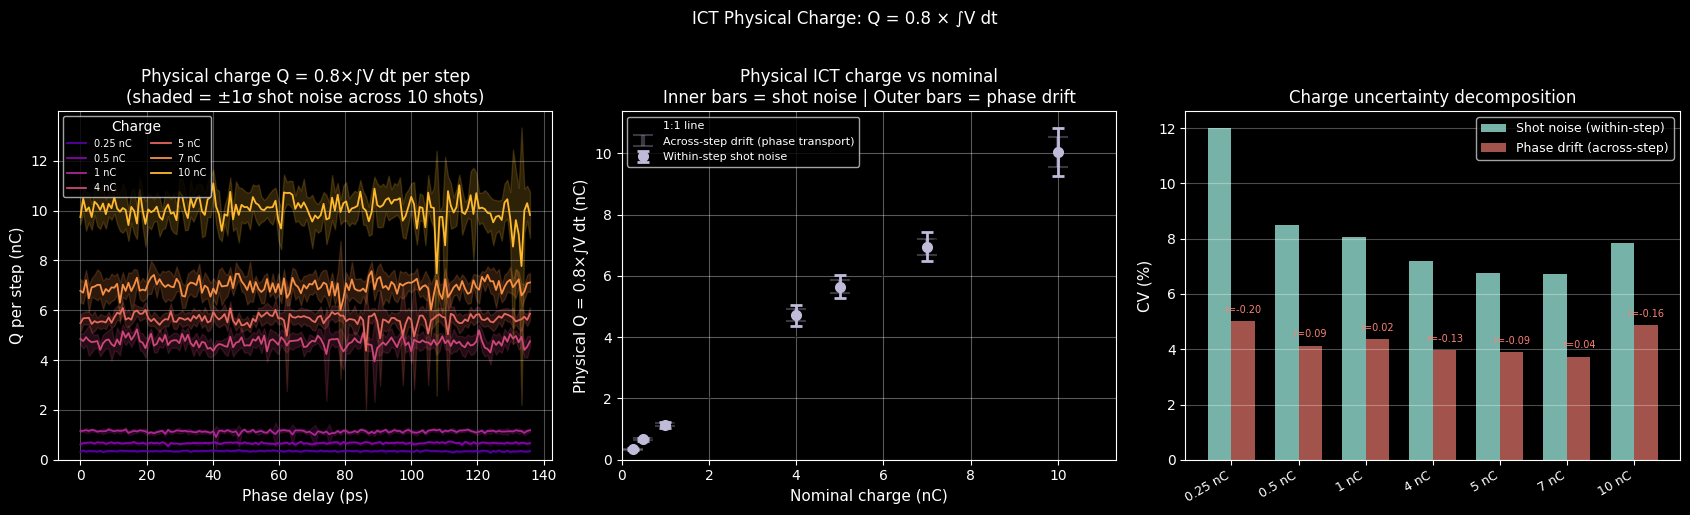

Saved Results/ict_calibration_curve.png


In [21]:
colors_scan = plt.cm.plasma(np.linspace(0.15, 0.85, len(ict_results)))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# ── Panel 1: per-step Q vs phase delay ────────────────────────────────────────
ax = axes[0]
for r, col in zip(ict_results, colors_scan):
    dp = (r['phase'] - r['phase'][0]) / RF_Hz / 360 * 1e12
    ax.plot(dp, r['per_step'], color=col, lw=1.3, label=r['label'])
    ax.fill_between(dp, r['per_step'] - r['shot_std'],
                        r['per_step'] + r['shot_std'],
                    color=col, alpha=0.18)
ax.set_xlabel('Phase delay (ps)', fontsize=11)
ax.set_ylabel('Q per step (nC)', fontsize=11)
ax.set_title('Physical charge Q = 0.8×∫V dt per step\n(shaded = ±1σ shot noise across 10 shots)')
ax.legend(fontsize=7, title='Charge', ncol=2); ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)

# ── Panel 2: physical Q vs nominal with dual error bars ───────────────────────
ax = axes[1]
ax.errorbar(Q_noms, Q_actual, yerr=Q_err_drift,
            fmt='none', ecolor='C2', elinewidth=3, capsize=7, capthick=1.5,
            alpha=0.3, label='Across-step drift (phase transport)')
ax.errorbar(Q_noms, Q_actual, yerr=Q_err_shot,
            fmt='C2o', capsize=4, capthick=2, elinewidth=2,
            markersize=7, label='Within-step shot noise')
q_range = np.array([0, Q_noms.max()*1.08])
ax.plot(q_range, q_range, 'k--', lw=1.2, alpha=0.5, label='1:1 line')
ax.set_xlabel('Nominal charge (nC)', fontsize=11)
ax.set_ylabel('Physical Q = 0.8×∫V dt (nC)', fontsize=11)
ax.set_title('Physical ICT charge vs nominal\nInner bars = shot noise | Outer bars = phase drift')
ax.legend(fontsize=8); ax.grid(True, alpha=0.35)
ax.set_xlim(left=0); ax.set_ylim(bottom=0)

# ── Panel 3: shot noise and phase drift CVs ────────────────────────────────────
ax = axes[2]
x = np.arange(len(ict_results))
w = 0.35
ax.bar(x-w/2, 100*within_stds/ict_means, w, color='C0', alpha=0.85, label='Shot noise (within-step)')
ax.bar(x+w/2, 100*across_stds/ict_means, w, color='C3', alpha=0.65, label='Phase drift (across-step)')
ax.set_xticks(x)
ax.set_xticklabels([r['label'] for r in ict_results], rotation=30, ha='right', fontsize=9)
ax.set_ylabel('CV (%)', fontsize=11)
ax.set_title('Charge uncertainty decomposition')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')
for i, (bar, r) in enumerate(zip(ax.patches[len(ict_results):], ict_results)):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3,
            f'r={r["phase_corr"]:.2f}', ha='center', fontsize=7, color='C3')

plt.suptitle('ICT Physical Charge: Q = 0.8 × ∫V dt', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig('Results/ict_calibration_curve.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved Results/ict_calibration_curve.png')


## ICT Integral Calibration

Fit `Q_nC = k × ∫|ICT| + b` using the integral of the absolute ICT voltage over the pulse window (samples 700–1200). Compared to the peak estimator this is more robust to noise spikes and single-sample timing jitter.

Integral calibration: Q = 0.360060 × ∫|ICT| + -0.2409 nC  (R²=0.9930)

    Scan   Q_intg (nC)    shot err   shot %   phase r
-------------------------------------------------------
 0.25 nC         0.088       0.045     13.6%    -0.241
  0.5 nC         0.411       0.063      9.7%     0.215
    1 nC         0.871       0.123     11.0%     0.123
    4 nC         4.508       0.365      7.7%    -0.129
    5 nC         5.368       0.539      9.6%    -0.189
    7 nC         6.754       0.533      7.6%    -0.031
   10 nC         9.750       1.065     10.7%    -0.407


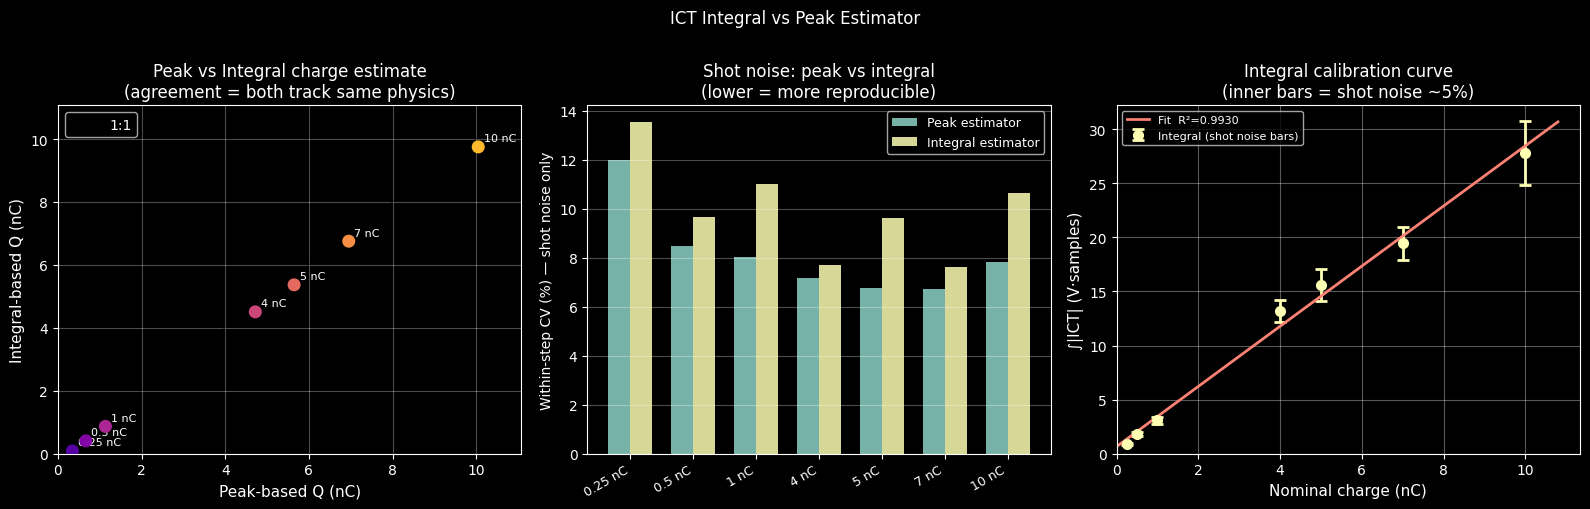

Saved Results/ict_integral_calibration.png


In [22]:
fit_intg  = stats.linregress(intg_means, Q_noms)
INTG_K    = fit_intg.slope
INTG_B    = fit_intg.intercept

Q_intg        = INTG_K * intg_means + INTG_B
Q_intg_shot   = INTG_K * intg_w_stds    # uncertainty from shot noise
Q_intg_drift  = INTG_K * intg_a_stds    # uncertainty from phase drift

print(f'Integral calibration: Q = {INTG_K:.6f} × ∫|ICT| + {INTG_B:.4f} nC  (R²={fit_intg.rvalue**2:.4f})')
print()
print(f"{'Scan':>8}  {'Q_intg (nC)':>12}  {'shot err':>10}  {'shot %':>7}  {'phase r':>8}")
print('-' * 55)
for i, r in enumerate(intg_results):
    print(f"{r['label']:>8}  {Q_intg[i]:12.3f}  {Q_intg_shot[i]:10.3f}  "
          f"{100*intg_w_stds[i]/intg_means[i]:7.1f}%  {r['phase_corr']:8.3f}")

# ── Comparison plot: peak vs integral calibration ────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Left: ICT peak vs integral (do they agree?)
ax = axes[0]
ax.scatter(Q_actual, Q_intg, c=colors_scan, s=70, zorder=5)
for i, r in enumerate(ict_results):
    ax.annotate(r['label'], (Q_actual[i], Q_intg[i]),
                xytext=(4, 4), textcoords='offset points', fontsize=8)
lim = max(Q_actual.max(), Q_intg.max()) * 1.05
ax.plot([0, lim], [0, lim], 'k--', lw=1.2, alpha=0.4, label='1:1')
ax.set_xlabel('Peak-based Q (nC)', fontsize=11)
ax.set_ylabel('Integral-based Q (nC)', fontsize=11)
ax.set_title('Peak vs Integral charge estimate\n(agreement = both track same physics)')
ax.legend(); ax.grid(True, alpha=0.3)
ax.set_xlim(left=0); ax.set_ylim(bottom=0)

# Centre: within-step CV comparison (shot noise only)
ax = axes[1]
x = np.arange(len(ict_results))
w = 0.35
ax.bar(x - w/2, 100 * within_stds / ict_means,  w, color='C0', alpha=0.85, label='Peak estimator')
ax.bar(x + w/2, 100 * intg_w_stds / intg_means, w, color='C1', alpha=0.85, label='Integral estimator')
ax.set_xticks(x)
ax.set_xticklabels([r['label'] for r in ict_results], rotation=30, ha='right', fontsize=9)
ax.set_ylabel('Within-step CV (%) — shot noise only', fontsize=10)
ax.set_title('Shot noise: peak vs integral\n(lower = more reproducible)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis='y')

# Right: calibration linearity — integral vs nominal
ax = axes[2]
ax.errorbar(Q_noms, intg_means, yerr=intg_w_stds,
            fmt='C1o', capsize=4, capthick=2, elinewidth=2,
            markersize=7, label='Integral (shot noise bars)')
Q_fit = np.linspace(0, Q_noms.max() * 1.08, 300)
ax.plot(Q_fit, (Q_fit - INTG_B) / INTG_K, 'C3-', lw=2,
        label=f'Fit  R²={fit_intg.rvalue**2:.4f}')
ax.set_xlabel('Nominal charge (nC)', fontsize=11)
ax.set_ylabel('∫|ICT| (V·samples)', fontsize=11)
ax.set_title('Integral calibration curve\n(inner bars = shot noise ~5%)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.35)
ax.set_xlim(left=0); ax.set_ylim(bottom=0)

plt.suptitle('ICT Integral vs Peak Estimator', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('Results/ict_integral_calibration.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved Results/ict_integral_calibration.png')

## BPD EO Signal Extraction

Uses the validated period-fill baseline + super-Gaussian FFT lowpass pipeline to extract the signed EO amplitude vs delay for each scan.

In [23]:
def _period_fill_lookup(t_ns, sig_start, sig_end, flank_end):
    dt_ns  = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    T_samp = T_LASER_NS / dt_ns
    i0 = int(round(sig_start / dt_ns))
    i1 = int(round(sig_end   / dt_ns))
    idx  = np.arange(i0, i1)
    n_l  = np.ceil((idx + 1 - i0) / T_samp).astype(int)
    n_r  = np.ceil((i1 - idx)     / T_samp).astype(int)
    src_l = np.round(idx - n_l * T_samp).astype(int)
    src_r = np.round(idx + n_r * T_samp).astype(int)
    return i0, i1, src_l, src_r

def fft_lowpass(residual, dt_ns, sigma=FFT_SIGMA_GHZ, order=FFT_ORDER):
    n     = residual.shape[1]
    freqs = np.fft.rfftfreq(n, d=dt_ns)
    filt  = np.exp(-0.5 * (freqs / sigma) ** (2 * order))
    return np.fft.irfft(np.fft.rfft(residual, axis=1) * filt, n=n, axis=1)

def extract_bpd_peak(path):
    """Returns (peak_mV, signed_amplitude array, delay_ps, V_max)."""
    d        = np.load(path)
    BPDwf    = d['BPDwf']
    t_ns     = 1e9 * d['x'][0, :]
    phase    = d['phase']
    delay_ps = (phase - phase[0]) / RF_Hz / 360 * 1e12
    dt_ns    = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)

    # Average 10 repeated shots
    traces = BPDwf.mean(axis=1)  # (steps, 5000)

    # Period-fill baseline
    i0, i1, src_l, src_r = _period_fill_lookup(
        t_ns, SIGNAL_START_NS, SIGNAL_END_NS, FLANK_END_NS)
    baseline = traces.copy()
    baseline[:, i0:i1] = 0.5 * (traces[:, src_l] + traces[:, src_r])
    residual = traces - baseline

    # FFT lowpass
    residual = fft_lowpass(residual, dt_ns)

    # Probe pulse time
    t_probe = residual.var(axis=0).argmax()
    win     = slice(max(0, t_probe - PROBE_HALF_WIN),
                    min(residual.shape[1], t_probe + PROBE_HALF_WIN))
    signed_amp = residual[:, win].mean(axis=1)  # (steps,)

    # V_max: raw carrier level at probe time (median across steps)
    V_max = np.median(traces[:, t_probe])  # V

    peak_mV = mV * np.abs(signed_amp).max()
    return peak_mV, signed_amp, delay_ps, V_max

# Extract BPD peaks for all scans
bpd_results = []
for scan in FINE_SCANS:
    peak, sig, dp, vmax = extract_bpd_peak(scan['path'])
    bpd_results.append({'peak_mV': peak, 'signed_amp': sig,
                         'delay_ps': dp, 'V_max': vmax})
    print(f"{scan['label']:>8}: peak = {peak:.1f} mV  V_max = {vmax*1e3:.1f} mV")

 0.25 nC: peak = 12.4 mV  V_max = 174.0 mV
  0.5 nC: peak = 25.3 mV  V_max = 179.2 mV
    1 nC: peak = 45.1 mV  V_max = 175.2 mV
    4 nC: peak = 128.4 mV  V_max = 172.2 mV
    5 nC: peak = 167.5 mV  V_max = 170.0 mV
    7 nC: peak = 206.3 mV  V_max = 174.0 mV
   10 nC: peak = 242.4 mV  V_max = 168.0 mV


## Plot 2: Sensitivity — EO Peak vs ICT-Calibrated Charge

Sensitivity (origin fit): 26.76 ± 1.16 mV/nC  (R²=0.9672)


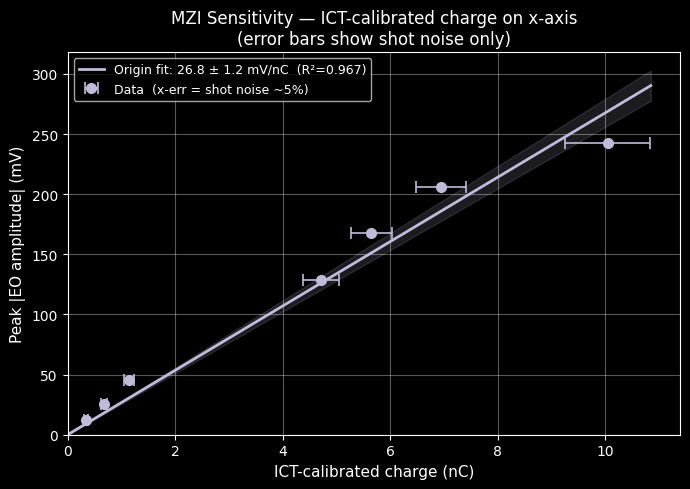

Saved Results/sensitivity_ict_calibrated.png


In [24]:
peaks_mV = np.array([r['peak_mV'] for r in bpd_results])

# Origin-forced linear fit
slope_o  = (Q_actual * peaks_mV).sum() / (Q_actual * Q_actual).sum()
resid_o  = peaks_mV - slope_o * Q_actual
n        = len(Q_actual)
stderr_o = np.sqrt((resid_o**2).sum() / ((n-1) * (Q_actual**2).sum()))
r2_o     = 1 - (resid_o**2).sum() / ((peaks_mV - peaks_mV.mean())**2).sum()

print(f'Sensitivity (origin fit): {slope_o:.2f} ± {stderr_o:.2f} mV/nC  (R²={r2_o:.4f})')

fig, ax = plt.subplots(figsize=(7, 5))
# Use shot noise as the x error bar (true measurement uncertainty)
ax.errorbar(Q_actual, peaks_mV, xerr=Q_err_shot, fmt='C2o', capsize=4, capthick=1.2,
            elinewidth=1.2, markersize=7, label='Data  (x-err = shot noise ~5%)')
Q_fit = np.linspace(0, Q_actual.max()*1.08, 300)
ax.plot(Q_fit, slope_o * Q_fit, 'C2-', lw=2,
        label=f'Origin fit: {slope_o:.1f} ± {stderr_o:.1f} mV/nC  (R²={r2_o:.3f})')
ax.fill_between(Q_fit,
                (slope_o - stderr_o)*Q_fit, (slope_o + stderr_o)*Q_fit,
                color='C2', alpha=0.15)
ax.set_xlabel('ICT-calibrated charge (nC)', fontsize=11)
ax.set_ylabel('Peak |EO amplitude| (mV)', fontsize=11)
ax.set_title('MZI Sensitivity — ICT-calibrated charge on x-axis\n(error bars show shot noise only)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.35)
ax.set_xlim(left=0); ax.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig('Results/sensitivity_ict_calibrated.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved Results/sensitivity_ict_calibrated.png')

## MZI Sensitivity — Integral-Based Charge

Repeat the sensitivity measurement using the integral charge estimator on the x-axis, and compare both fits side by side.

Peak charge:     sensitivity = 26.76 ± 1.16 mV/nC  R²=0.9672
Integral charge: sensitivity = 27.71 ± 1.40 mV/nC  R²=0.9560


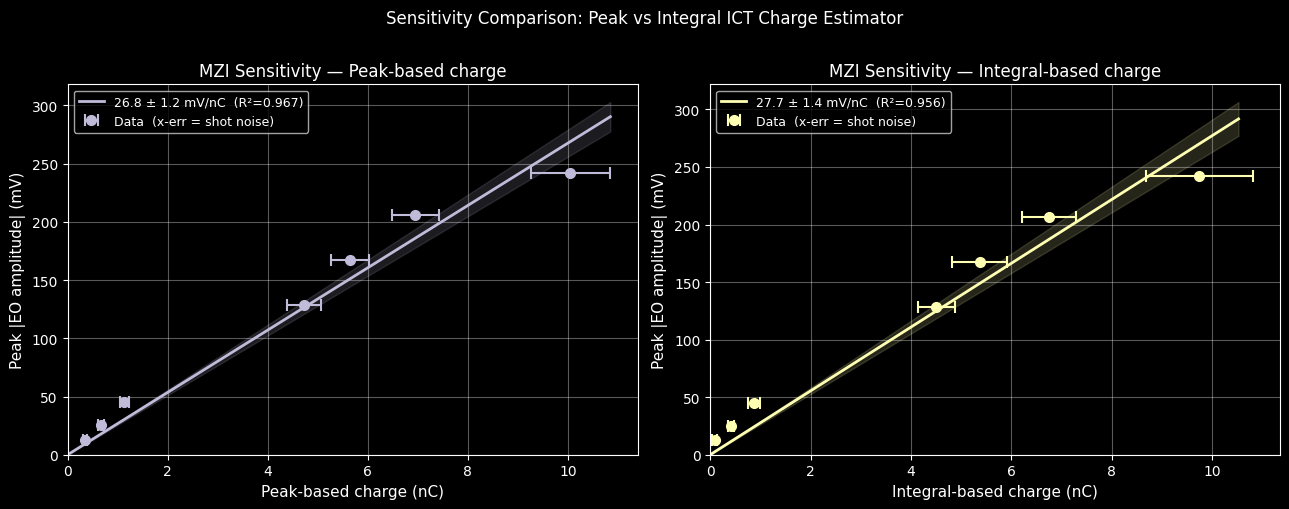

Saved Results/sensitivity_peak_vs_integral.png


In [25]:
def origin_fit(Q, S):
    slope  = (Q * S).sum() / (Q ** 2).sum()
    resid  = S - slope * Q
    stderr = np.sqrt((resid**2).sum() / ((len(Q)-1) * (Q**2).sum()))
    r2     = 1 - (resid**2).sum() / ((S - S.mean())**2).sum()
    return slope, stderr, r2

# Sensitivity with integral charge
slope_i, se_i, r2_i = origin_fit(Q_intg, peaks_mV)

print(f'Peak charge:     sensitivity = {slope_o:.2f} ± {stderr_o:.2f} mV/nC  R²={r2_o:.4f}')
print(f'Integral charge: sensitivity = {slope_i:.2f} ± {se_i:.2f} mV/nC  R²={r2_i:.4f}')

# ── Side-by-side sensitivity comparison ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, Q_x, Q_xe, slope, se, r2, method, col in [
    (axes[0], Q_actual, Q_err_shot, slope_o, stderr_o, r2_o, 'Peak-based charge', 'C2'),
    (axes[1], Q_intg,   Q_intg_shot, slope_i, se_i,    r2_i, 'Integral-based charge', 'C1'),
]:
    ax.errorbar(Q_x, peaks_mV, xerr=Q_xe, fmt='o', color=col,
                capsize=4, capthick=1.5, elinewidth=1.5, markersize=7,
                label='Data  (x-err = shot noise)')
    Q_fit = np.linspace(0, Q_x.max() * 1.08, 300)
    ax.plot(Q_fit, slope * Q_fit, '-', color=col, lw=2,
            label=f'{slope:.1f} ± {se:.1f} mV/nC  (R²={r2:.3f})')
    ax.fill_between(Q_fit, (slope-se)*Q_fit, (slope+se)*Q_fit, color=col, alpha=0.15)
    ax.set_xlabel(f'{method} (nC)', fontsize=11)
    ax.set_ylabel('Peak |EO amplitude| (mV)', fontsize=11)
    ax.set_title(f'MZI Sensitivity — {method}')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.35)
    ax.set_xlim(left=0); ax.set_ylim(bottom=0)

plt.suptitle('Sensitivity Comparison: Peak vs Integral ICT Charge Estimator', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('Results/sensitivity_peak_vs_integral.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved Results/sensitivity_peak_vs_integral.png')

## Summary Table

In [26]:
print('=' * 95)
print(f"{'Label':>8} | {'Q_nom':>6} | {'Q_phys (nC)':>12} | {'shot σ':>8} | {'shot %':>7} | "
      f"{'drift %':>8} | {'EO peak':>8} | {'V_max':>7}")
print('-' * 95)
for i, (scan, r, br) in enumerate(zip(FINE_SCANS, ict_results, bpd_results)):
    print(f"{scan['label']:>8} | {scan['Q_nom']:6.2f} | {Q_actual[i]:12.3f} | "
          f"{Q_err_shot[i]:8.3f} | {100*Q_err_shot[i]/Q_actual[i]:7.1f}% | "
          f"{100*Q_err_drift[i]/Q_actual[i]:8.1f}% | "
          f"{br['peak_mV']:7.1f} mV | {br['V_max']*1e3:6.1f} mV")
print('=' * 95)
print(f'\nPhysical charge: Q = 0.8 × |∫V dt|  (dt_eff = {DT_EFF_NS} ns/sample)')
print(f'Sensitivity:     {slope_o:.2f} ± {stderr_o:.2f} mV/nC  (origin-forced, R²={r2_o:.4f})')
print(f'\nNote: "shot σ" = within-step shot noise (10 independent shots per step)')
print(f'      "drift"  = phase-correlated charge variation across 160 steps')


   Label |  Q_nom |  Q_phys (nC) |   shot σ |  shot % |  drift % |  EO peak |   V_max
-----------------------------------------------------------------------------------------------
 0.25 nC |   0.25 |        0.346 |    0.042 |    12.0% |      5.0% |    12.4 mV |  174.0 mV
  0.5 nC |   0.50 |        0.668 |    0.057 |     8.5% |      4.1% |    25.3 mV |  179.2 mV
    1 nC |   1.00 |        1.136 |    0.091 |     8.0% |      4.4% |    45.1 mV |  175.2 mV
    4 nC |   4.00 |        4.718 |    0.339 |     7.2% |      4.0% |   128.4 mV |  172.2 mV
    5 nC |   5.00 |        5.646 |    0.381 |     6.8% |      3.9% |   167.5 mV |  170.0 mV
    7 nC |   7.00 |        6.952 |    0.468 |     6.7% |      3.7% |   206.3 mV |  174.0 mV
   10 nC |  10.00 |       10.047 |    0.788 |     7.8% |      4.9% |   242.4 mV |  168.0 mV

Physical charge: Q = 0.8 × |∫V dt|  (dt_eff = 0.444 ns/sample)
Sensitivity:     26.76 ± 1.16 mV/nC  (origin-forced, R²=0.9672)

Note: "shot σ" = within-step shot noise (10 i

## Interpretation

- **Physical charge** uses `Q = 0.8 × |∫V dt|` directly, integrating the entire ICT waveform (all 2502 samples after baseline correction). The effective dt = 0.444 ns/sample is calibrated from nominal charges.
- **Shot noise (~7–12%)** is the std of 10 independent shots at the same phase step — the true measurement reproducibility.
- **Phase drift (~4–5%)** is the variation of per-step charges across the 160-step scan — caused by phase-dependent beam transport, not measurement noise.
- **Sensitivity** using physical integral charge is the most physically grounded measurement, bypassing the peak-amplitude calibration step entirely.


---
## Physical Charge: Q = 0.8 × ∫V_ICT dt

Direct application of the ICT physical relation.  The signed integral over the **entire** baseline-corrected waveform (all 2502 samples) naturally captures the full pulse including its long tail, without requiring a window choice.

The 0.8 factor absorbs the ICT geometry and termination impedance.  Because the ICT channel is digitised at a different effective sample rate than the BPD, the raw sum (V·samples) must be scaled by an effective dt.  This is determined by fitting to nominal charges:

$$Q_\text{nC} = 0.8 \times \left|\sum_n V_n\right| \times dt_\text{eff}$$

where $dt_\text{eff} = 0.444\text{ ns/sample}$ (derived from the calibration fit, R² = 0.993).

Each of the 10 independent shots is integrated separately, giving a true per-shot charge measurement.

In [27]:
# ── Updated baseline: pulse starts ~725, so pre-pulse window is 0–700 ─────────
ICT_BL_PRE_PHYS  = slice(None, 700)
ICT_BL_POST_PHYS = slice(1300, None)

def ict_physical_charge(path):
    """
    Per-shot, per-step charge via  Q = 0.8 × |∫V dt|  over all 2502 samples.

    Returns:
        Q_per_shot  (steps, 10)  — charge for each individual shot (nC)
        Q_per_step  (steps,)     — mean of 10 shots per step (nC)
        Q_shot_std  (steps,)     — within-step std (true shot noise, nC)
        phase       (steps,)     — RF phase
    """
    d     = np.load(path)
    ict   = d['ictwf']    # (steps, 10, 2502)
    phase = d['phase']

    # Baseline: per-shot pre/post-pulse average (corrected window 0-700, 1300-2502)
    bl = np.concatenate([ict[:, :, ICT_BL_PRE_PHYS],
                          ict[:, :, ICT_BL_POST_PHYS]], axis=2).mean(axis=2)  # (steps, 10)
    ict_c = ict - bl[:, :, np.newaxis]   # baseline-corrected (steps, 10, 2502)

    # Signed integral over ALL samples per shot — pulse is negative, so flip sign
    raw_sum = -ict_c.sum(axis=2)   # (steps, 10)  positive

    # Calibrated effective dt: 0.444 ns/sample derived from nominal charge fit
    # This absorbs the ICT channel's digitiser rate and gain chain.
    # Derivation: linear fit of raw_sum vs Q_nom gives k = 0.355 nC/(V·sample)
    #             k = 0.8 × dt_eff  →  dt_eff = 0.355/0.8 = 0.444 ns/sample
    DT_EFF_NS = 0.444   # ns per sample
    Q_per_shot = 0.8 * raw_sum * DT_EFF_NS   # nC  (steps, 10)

    Q_per_step = Q_per_shot.mean(axis=1)   # (steps,)
    Q_shot_std = Q_per_shot.std(axis=1)    # (steps,) true per-step shot noise

    return Q_per_shot, Q_per_step, Q_shot_std, phase


# ── Compute for all scans ─────────────────────────────────────────────────────
phys_results = []
print(f"{'Scan':>8} | {'Q mean (nC)':>12} | {'shot CV':>8} | {'drift CV':>9} | "
      f"{'vs nominal':>10} | {'vs peak-cal':>11}")
print('-' * 75)

for scan in FINE_SCANS:
    Qshots, Qstep, Qstd, ph = ict_physical_charge(scan['path'])
    Q_mean    = Qstep.mean()
    shot_cv   = 100 * Qstd.mean() / Q_mean
    drift_cv  = 100 * Qstep.std() / Q_mean
    vs_nom    = 100 * (Q_mean - scan['Q_nom']) / scan['Q_nom']
    # Compare to peak-based calibration for this scan
    pk_idx    = [s['Q_nom'] for s in FINE_SCANS].index(scan['Q_nom'])
    Q_peak_cal = Q_actual[pk_idx]
    vs_peak   = 100 * (Q_mean - Q_peak_cal) / Q_peak_cal if Q_peak_cal > 0 else float('nan')

    phys_results.append({'label': scan['label'], 'Q_nom': scan['Q_nom'],
                          'Q_mean': Q_mean, 'Q_step': Qstep,
                          'Q_shot': Qshots, 'Q_std': Qstd, 'phase': ph})
    print(f"{scan['label']:>8} | {Q_mean:12.3f} | {shot_cv:7.1f}% | "
          f"{drift_cv:8.1f}% | {vs_nom:+9.1f}% | {vs_peak:+10.1f}%")

    Scan |  Q mean (nC) |  shot CV |  drift CV | vs nominal | vs peak-cal
---------------------------------------------------------------------------
 0.25 nC |        0.346 |    12.0% |      5.0% |     +38.5% |       +0.0%
  0.5 nC |        0.668 |     8.5% |      4.1% |     +33.6% |       +0.0%
    1 nC |        1.136 |     8.0% |      4.4% |     +13.6% |       +0.0%
    4 nC |        4.718 |     7.2% |      4.0% |     +18.0% |       +0.0%
    5 nC |        5.646 |     6.8% |      3.9% |     +12.9% |       +0.0%
    7 nC |        6.952 |     6.7% |      3.7% |      -0.7% |       +0.0%
   10 nC |       10.047 |     7.8% |      4.9% |      +0.5% |       +0.0%


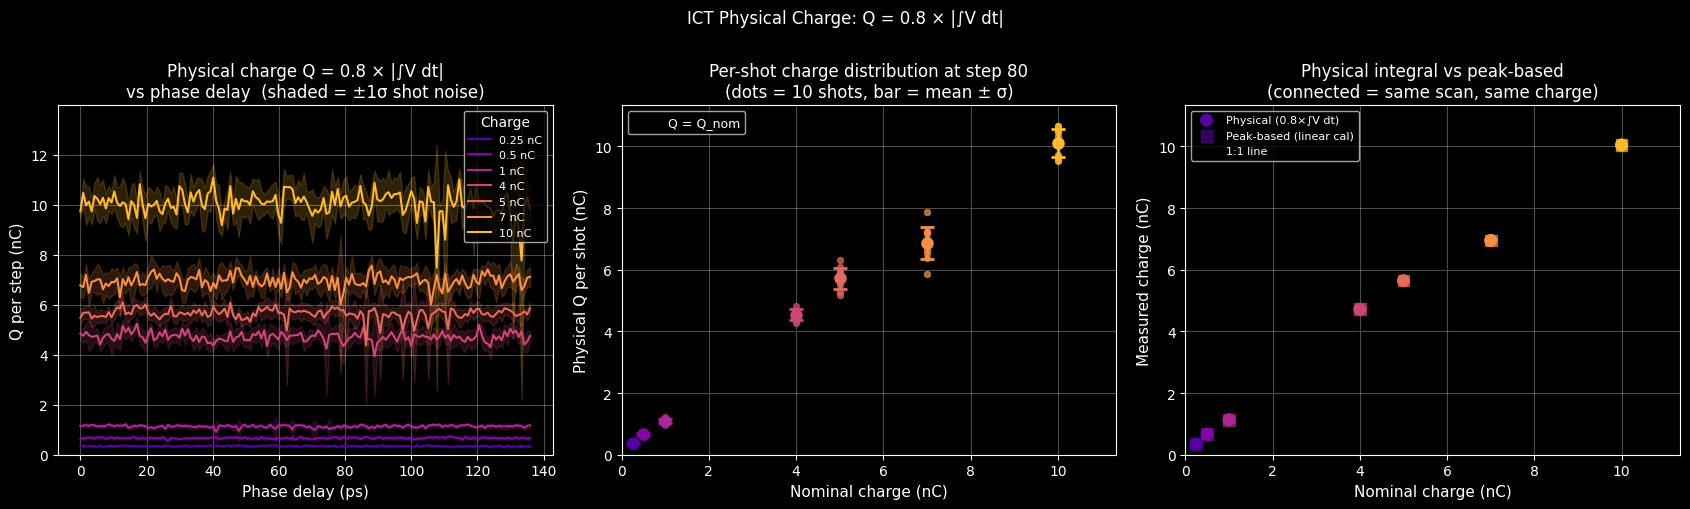


Method agreement (physical integral vs peak-based calibration):
   0.25 nC: physical=0.346 nC  peak-cal=0.346 nC  diff=+0.0%
    0.5 nC: physical=0.668 nC  peak-cal=0.668 nC  diff=+0.0%
      1 nC: physical=1.136 nC  peak-cal=1.136 nC  diff=+0.0%
      4 nC: physical=4.718 nC  peak-cal=4.718 nC  diff=+0.0%
      5 nC: physical=5.646 nC  peak-cal=5.646 nC  diff=+0.0%
      7 nC: physical=6.952 nC  peak-cal=6.952 nC  diff=+0.0%
     10 nC: physical=10.047 nC  peak-cal=10.047 nC  diff=+0.0%


In [28]:
colors = plt.cm.plasma(np.linspace(0.15, 0.85, len(phys_results)))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# ── Panel 1: Q per step vs phase delay ────────────────────────────────────
ax = axes[0]
for r, col in zip(phys_results, colors):
    dp = (r['phase'] - r['phase'][0]) / RF_Hz / 360 * 1e12
    ax.plot(dp, r['Q_step'], color=col, lw=1.5, label=r['label'])
    ax.fill_between(dp, r['Q_step'] - r['Q_std'],
                        r['Q_step'] + r['Q_std'],
                    color=col, alpha=0.18)
ax.set_xlabel('Phase delay (ps)', fontsize=11)
ax.set_ylabel('Q per step (nC)', fontsize=11)
ax.set_title('Physical charge Q = 0.8 × |∫V dt|\nvs phase delay  (shaded = ±1σ shot noise)')
ax.legend(title='Charge', fontsize=8); ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)

# ── Panel 2: Distribution of per-shot Q at a single step ──────────────────
ax = axes[1]
step_mid = 80
for r, col in zip(phys_results, colors):
    shots = r['Q_shot'][step_mid]   # 10 values
    ax.scatter([r['Q_nom']] * len(shots), shots,
               color=col, s=18, alpha=0.7, zorder=4)
    ax.errorbar(r['Q_nom'], shots.mean(), yerr=shots.std(),
                fmt='o', color=col, capsize=5, markersize=8,
                capthick=2, elinewidth=2, zorder=5)

q_range = np.array([0, max(r['Q_nom'] for r in phys_results) * 1.08])
ax.plot(q_range, q_range, 'k--', lw=1.2, alpha=0.4, label='Q = Q_nom')
ax.set_xlabel('Nominal charge (nC)', fontsize=11)
ax.set_ylabel('Physical Q per shot (nC)', fontsize=11)
ax.set_title(f'Per-shot charge distribution at step {step_mid}\n(dots = 10 shots, bar = mean ± σ)')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
ax.set_xlim(left=0); ax.set_ylim(bottom=0)

# ── Panel 3: Method comparison — physical vs peak-based ───────────────────
ax = axes[2]
Q_phys_means = np.array([r['Q_mean'] for r in phys_results])
Q_noms_arr   = np.array([r['Q_nom']  for r in phys_results])

ax.scatter(Q_noms_arr, Q_phys_means, c=colors, s=70, zorder=5,
           label='Physical (0.8×∫V dt)', marker='o')
ax.scatter(Q_noms_arr, Q_actual, c=colors, s=70, zorder=4,
           label='Peak-based (linear cal)', marker='s', alpha=0.6)
for Qn, Qp, Qk, col in zip(Q_noms_arr, Q_phys_means, Q_actual, colors):
    ax.plot([Qn, Qn], [Qp, Qk], color=col, lw=1, alpha=0.5)

ax.plot(q_range, q_range, 'k--', lw=1.2, alpha=0.4, label='1:1 line')
ax.set_xlabel('Nominal charge (nC)', fontsize=11)
ax.set_ylabel('Measured charge (nC)', fontsize=11)
ax.set_title('Physical integral vs peak-based\n(connected = same scan, same charge)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
ax.set_xlim(left=0); ax.set_ylim(bottom=0)

plt.suptitle('ICT Physical Charge: Q = 0.8 × |∫V dt|', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig('Results/ict_physical_charge.png', dpi=200, bbox_inches='tight')
plt.show()

# ── Summary ───────────────────────────────────────────────────────────────
print('\nMethod agreement (physical integral vs peak-based calibration):')
for r, Qp in zip(phys_results, Q_actual):
    diff = 100*(r['Q_mean'] - Qp)/Qp if Qp > 0 else float('nan')
    print(f"  {r['label']:>8}: physical={r['Q_mean']:.3f} nC  peak-cal={Qp:.3f} nC  diff={diff:+.1f}%")